# Analyze Seasons over time from across all models and ERA5

In [47]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

import matplotlib.ticker as mticker
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import scipy.stats as stats
from sklearn import linear_model
import statsmodels.api as sm
import seaborn as sns

import pymannkendall as mk

# to get rid of runtime warnings when OLS fits hit a divide by zero - handled by setting R2 and p-vals appropriately
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## Load in Model Season Length Data

In [12]:
file_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/ACCESS-ESM1-5/regridded/Seasons/1961-2014_ACCESS-ESM1-5_historical_season_stats.nc'
ds_model_hist = xr.open_mfdataset(file_path)
ds_model_hist.load()
ds_model_hist

<xarray.Dataset> Size: 4GB
Dimensions:       (model: 1, experiment: 1, time: 54, lat: 721, lon: 1440)
Coordinates:
  * model         (model) <U13 52B 'ACCESS-ESM1-5'
  * experiment    (experiment) <U10 40B 'historical'
  * time          (time) datetime64[ns] 432B 1961-01-01 ... 2014-01-01
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    WinterStart   (model, experiment, time, lat, lon) float64 449MB nan ... nan
    WinterEnd     (model, experiment, time, lat, lon) float64 449MB nan ... nan
    WinterLength  (model, experiment, time, lat, lon) float64 449MB nan ... nan
    SummerStart   (model, experiment, time, lat, lon) float64 449MB nan ... nan
    SummerEnd     (model, experiment, time, lat, lon) float64 449MB nan ... nan
    SummerLength  (model, experiment, time, lat, lon) float64 449MB nan ... nan
    SpringLength  (model, experiment, time, lat, lon) float64 449MB nan ... nan
    AutumnLength  (model, experiment, time, lat, lon) float64 449MB nan ... nan

In [13]:
file_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/ACCESS-ESM1-5/regridded/Seasons/2015-2099_ACCESS-ESM1-5_ssp245_season_stats.nc'
ds_model_ssp245 = xr.open_mfdataset(file_path)
ds_model_ssp245.load()
ds_model_ssp245

<xarray.Dataset> Size: 6GB
Dimensions:       (model: 1, experiment: 1, time: 85, lat: 721, lon: 1440)
Coordinates:
  * model         (model) <U13 52B 'ACCESS-ESM1-5'
  * experiment    (experiment) <U6 24B 'ssp245'
  * time          (time) datetime64[ns] 680B 2015-01-01 ... 2099-01-01
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    WinterStart   (model, experiment, time, lat, lon) float64 706MB nan ... nan
    WinterEnd     (model, experiment, time, lat, lon) float64 706MB nan ... nan
    WinterLength  (model, experiment, time, lat, lon) float64 706MB nan ... nan
    SummerStart   (model, experiment, time, lat, lon) float64 706MB nan ... nan
    SummerEnd     (model, experiment, time, lat, lon) float64 706MB nan ... nan
    SummerLength  (model, experiment, time, lat, lon) float64 706MB nan ... nan
    SpringLength  (model, experiment, time, lat, lon) float64 706MB nan ... nan
    AutumnLength  (model, experiment, time, lat, lon) float64 706MB nan ... nan

In [14]:
# find weights (this is a regular grid so we can use cos(latitude))
weights = np.cos(np.deg2rad(ds_model_hist.lat))
weights.name = "weights"

### Split by hemisphere

In [15]:
%%time

# takes 17 sec

# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -60 # this is as far S as the NEX data goes
sh_max = -23.5

# datasets of weighted averages for the midlatitudes
nh_model_hist = ds_model_hist.where(((ds_model_hist.lat >= nh_min) & (ds_model_hist.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])
sh_model_hist = ds_model_hist.where(((ds_model_hist.lat >= sh_min) & (ds_model_hist.lat <= sh_max))).weighted(weights).mean(dim=['lat','lon'])

nh_model_ssp245 = ds_model_ssp245.where(((ds_model_ssp245.lat >= nh_min) & (ds_model_ssp245.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])
sh_model_ssp245 = ds_model_ssp245.where(((ds_model_ssp245.lat >= sh_min) & (ds_model_ssp245.lat <= sh_max))).weighted(weights).mean(dim=['lat','lon'])


CPU times: user 7.67 s, sys: 7.06 s, total: 14.7 s
Wall time: 16.5 s


In [16]:
nh_model_hist

<xarray.Dataset> Size: 4kB
Dimensions:       (time: 54, experiment: 1, model: 1)
Coordinates:
  * time          (time) datetime64[ns] 432B 1961-01-01 ... 2014-01-01
  * experiment    (experiment) <U10 40B 'historical'
  * model         (model) <U13 52B 'ACCESS-ESM1-5'
Data variables:
    WinterStart   (model, experiment, time) float64 432B 149.1 150.5 ... 160.1
    WinterEnd     (model, experiment, time) float64 432B 253.1 241.8 ... 236.9
    WinterLength  (model, experiment, time) float64 432B 105.0 92.28 ... 77.73
    SummerStart   (model, experiment, time) float64 432B 158.3 156.7 ... 149.3
    SummerEnd     (model, experiment, time) float64 432B 249.1 249.1 ... 256.2
    SummerLength  (model, experiment, time) float64 432B 91.8 93.41 ... 107.9
    SpringLength  (model, experiment, time) float64 432B 0.0 86.59 ... 87.41
    AutumnLength  (model, experiment, time) float64 432B 82.98 84.47 ... 86.95

#### Plot NH

Text(0, 0.5, 'Length [Days]')

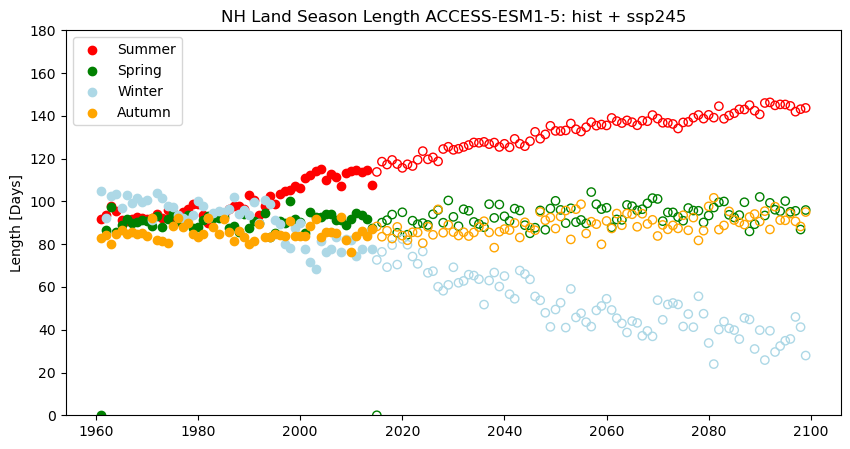

In [50]:
plt.figure(figsize=(10,5))
x_vals = nh_model_hist.time.dt.year.values
plt.scatter(x_vals, nh_model_hist.SummerLength, label="Summer", color="red")
plt.scatter(x_vals, nh_model_hist.SpringLength, label="Spring", color="green")
plt.scatter(x_vals, nh_model_hist.WinterLength, label="Winter", color="lightblue")
plt.scatter(x_vals, nh_model_hist.AutumnLength, label="Autumn", color="orange")

x_vals_ssp245 = nh_model_ssp245.time.dt.year.values
plt.scatter(x_vals_ssp245, nh_model_ssp245.SummerLength, label="", marker='o', facecolors='none', edgecolors='red')
plt.scatter(x_vals_ssp245, nh_model_ssp245.SpringLength, label="", marker='o', facecolors='none', edgecolors="green")
plt.scatter(x_vals_ssp245, nh_model_ssp245.WinterLength, label="", marker='o', facecolors='none', edgecolors="lightblue")
plt.scatter(x_vals_ssp245, nh_model_ssp245.AutumnLength, label="", marker='o', facecolors='none', edgecolors="orange")

plt.legend()
plt.ylim(0,180)
plt.title("NH Land Season Length ACCESS-ESM1-5: hist + ssp245")
plt.ylabel("Length [Days]")
#plt.show()
#plt.xlim(dt(1989,1,1),dt(2025,12,31))


## Load in ERA5 Season length data

In [33]:
file_path = '../../../../Data/ERA5-global/ERA5-2023-09-01-CoordFixed-LSM.nc'
ds_lsm = xr.open_dataset(file_path)
ds_lsm

<xarray.Dataset> Size: 8MB
Dimensions:  (lat: 721, lon: 1440)
Coordinates:
  * lat      (lat) float32 3kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float32 6kB -180.0 -179.8 -179.5 -179.2 ... 179.2 179.5 179.8
Data variables:
    lsm      (lat, lon) float64 8MB ...

In [44]:
# read era5 seasons in
input_path = '../../../../Data/ERA5-global/Analysis/New-Fourier/Seasons/1961-2025_ALL_season_stats.nc'
ds_era5 = xr.open_dataset(input_path)
# ds_era5 = ds_era5.drop_vars('Coastal')
# ds_era5 = ds_era5.merge(ds_lsm)
ds_era5.load()
#ds_era5

<xarray.Dataset> Size: 4GB
Dimensions:       (time: 65, lat: 721, lon: 1440)
Coordinates:
  * time          (time) datetime64[ns] 520B 1961-01-01 ... 2025-01-01
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    WinterStart   (time, lat, lon) float64 540MB 88.0 88.0 88.0 ... 219.0 219.0
    WinterEnd     (time, lat, lon) float64 540MB 125.0 125.0 ... 219.0 219.0
    WinterLength  (time, lat, lon) float64 540MB 38.0 38.0 38.0 ... 0.0 0.0 0.0
    SummerStart   (time, lat, lon) float64 540MB 135.0 135.0 ... 150.0 150.0
    SummerEnd     (time, lat, lon) float64 540MB 224.0 224.0 ... 252.0 252.0
    SummerLength  (time, lat, lon) float64 540MB 90.0 90.0 90.0 ... 103.0 103.0
    SpringLength  (time, lat, lon) float64 540MB 193.0 193.0 ... 137.0 137.0
    AutumnLength  (time, lat, lon) float64 540MB 0.0 0.0 0.0 ... 150.0 150.0
    lsm           (lat, lon) float64 8MB 1.0 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0 0.0

In [42]:
# write out complete dataset with LSM flags
# output_path = '../../../../Data/ERA5-global/Analysis/New-Fourier/Seasons/1961-2025_ALL_season_stats.nc'
# ds_era5.to_netcdf(output_path)

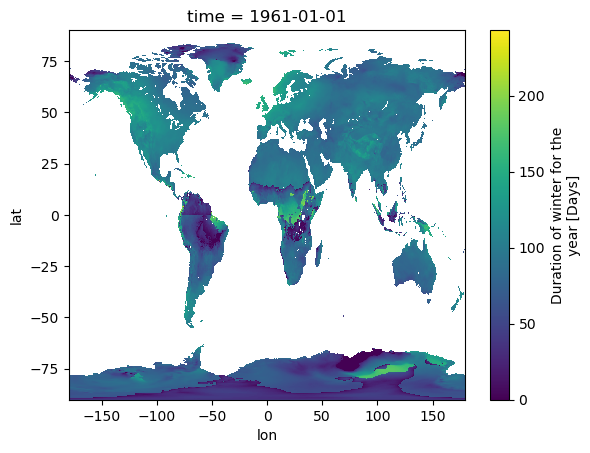

In [49]:
ds_era5.sel(time='1961').WinterLength.where(ds_era5.lsm > 0.5).plot()

## Weighted mean for NH and SH, and also make func for any grid square

In [51]:
# find weights (this is a regular grid so we can use cos(latitude))
weights = np.cos(np.deg2rad(ds_era5.lat))
weights.name = "weights"

### Restrict to LAND

In [52]:
%%time

# takes 7 sec

# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -60
sh_max = -23.5

# datasets of weighted averages for the midlatitudes
nh_era5 = ds_era5.where((ds_era5.lsm > 0.5) & 
                             ((ds_era5.lat >= nh_min) & (ds_era5.lat <= nh_max))).weighted(weights).mean(dim=['lat','lon'])

sh_era5 = ds_era5.where((ds_era5.lsm > 0.5) &  
                             ((ds_era5.lat >= sh_min) & (ds_era5.lat <= sh_max))).weighted(weights).mean(dim=['lat','lon'])



CPU times: user 3.51 s, sys: 2.88 s, total: 6.39 s
Wall time: 6.91 s


## Plot Model and ERA5 together

In [60]:
nh_model_hist.SummerLength.values[0][0]

array([ 91.79852827,  93.41371063,  97.62258117,  95.44757413,
        91.30074592,  90.72247742,  91.53888976,  92.82963001,
        92.17372723,  91.89463548,  92.46489576,  93.95407142,
        92.20739549,  95.86834177,  92.80612999,  90.78356543,
        95.0578218 ,  96.24140197,  98.64513604,  98.70777088,
        93.58181193,  90.08936262,  93.11840182,  92.58417946,
        93.96784864,  96.5147795 ,  97.85304321,  97.65822172,
        96.44793093, 103.05403006, 100.80688066,  93.4245484 ,
        97.66435985, 102.40671786,  98.82598516, 103.51691281,
       104.8132017 , 105.54296333, 107.37318355, 106.45296285,
       110.9752587 , 112.13688263, 114.05498432, 115.07953571,
       110.00815524, 113.03121021, 111.22952914, 107.06850528,
       113.42339447, 114.12055651, 114.48201302, 113.60442609,
       114.65469966, 107.85902685])

Text(0, 0.5, 'Length [Days]')

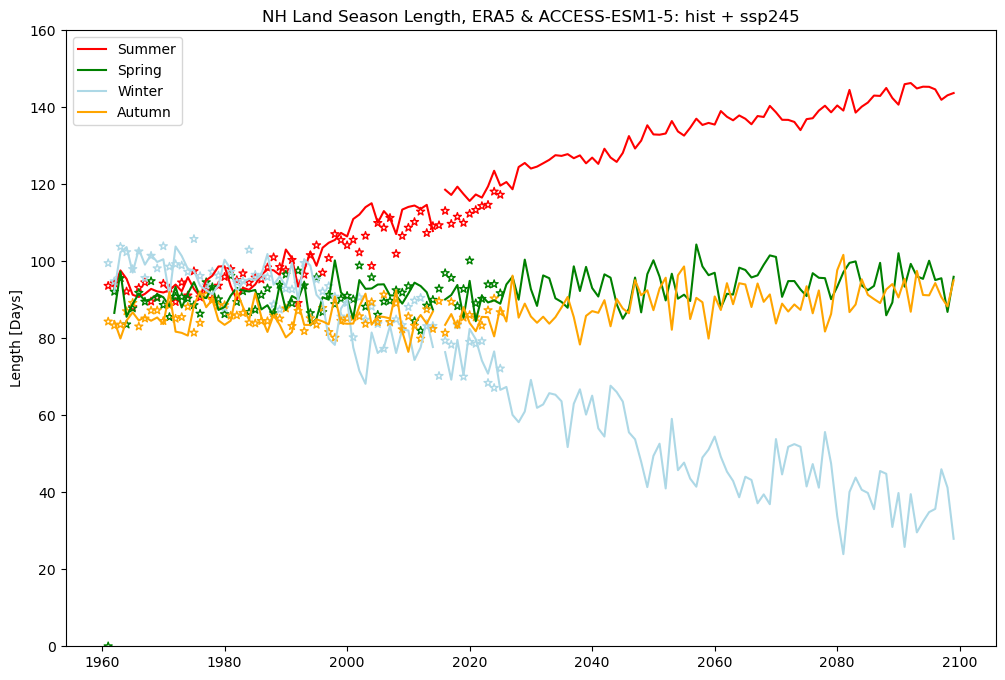

In [70]:
plt.figure(figsize=(12,8))
x_vals = nh_model_hist.time.dt.year.values
plot_dat = nh_model_hist.sel(time=slice('1962','2014'))
x_vals = plot_dat.time.dt.year.values
plt.plot(x_vals, plot_dat.SummerLength.values[0][0], label="Summer", color="red")
plt.plot(x_vals, plot_dat.SpringLength.values[0][0], label="Spring", color="green")
plt.plot(x_vals, plot_dat.WinterLength.values[0][0], label="Winter", color="lightblue")
plt.plot(x_vals, plot_dat.AutumnLength.values[0][0], label="Autumn", color="orange")

plot_dat_spp245 = nh_model_ssp245.sel(time=slice('2016','2099'))
x_vals_ssp245 = plot_dat_spp245.time.dt.year.values
plt.plot(x_vals_ssp245, plot_dat_spp245.SummerLength.values[0][0], color='red')
plt.plot(x_vals_ssp245, plot_dat_spp245.SpringLength.values[0][0], color="green")
plt.plot(x_vals_ssp245, plot_dat_spp245.WinterLength.values[0][0], color="lightblue")
plt.plot(x_vals_ssp245, plot_dat_spp245.AutumnLength.values[0][0], color="orange")

x_vals_era5 = nh_era5.time.dt.year.values
plt.scatter(x_vals_era5, nh_era5.SummerLength, label="", marker='*', facecolors='none', edgecolors='red')
plt.scatter(x_vals_era5, nh_era5.SpringLength, label="", marker='*', facecolors='none', edgecolors="green")
plt.scatter(x_vals_era5, nh_era5.WinterLength, label="", marker='*', facecolors='none', edgecolors="lightblue")
plt.scatter(x_vals_era5, nh_era5.AutumnLength, label="", marker='*', facecolors='none', edgecolors="orange")

plt.legend()
plt.ylim(0,160)
plt.title("NH Land Season Length, ERA5 & ACCESS-ESM1-5: hist + ssp245")
plt.ylabel("Length [Days]")
#plt.show()
#plt.xlim(dt(1989,1,1),dt(2025,12,31))


#### Just ERA5 and Historical

Text(0, 0.5, 'Length [Days]')

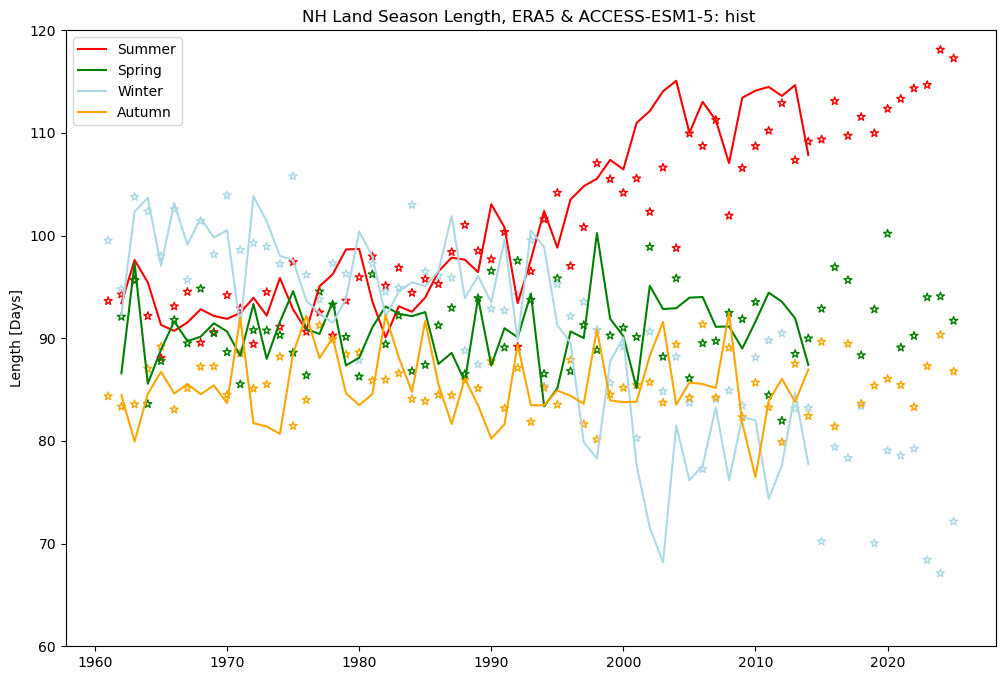

In [72]:
plt.figure(figsize=(12,8))
x_vals = nh_model_hist.time.dt.year.values
plot_dat = nh_model_hist.sel(time=slice('1962','2014'))
x_vals = plot_dat.time.dt.year.values
plt.plot(x_vals, plot_dat.SummerLength.values[0][0], label="Summer", color="red")
plt.plot(x_vals, plot_dat.SpringLength.values[0][0], label="Spring", color="green")
plt.plot(x_vals, plot_dat.WinterLength.values[0][0], label="Winter", color="lightblue")
plt.plot(x_vals, plot_dat.AutumnLength.values[0][0], label="Autumn", color="orange")

x_vals_era5 = nh_era5.time.dt.year.values
plt.scatter(x_vals_era5, nh_era5.SummerLength, label="", marker='*', facecolors='none', edgecolors='red')
plt.scatter(x_vals_era5, nh_era5.SpringLength, label="", marker='*', facecolors='none', edgecolors="green")
plt.scatter(x_vals_era5, nh_era5.WinterLength, label="", marker='*', facecolors='none', edgecolors="lightblue")
plt.scatter(x_vals_era5, nh_era5.AutumnLength, label="", marker='*', facecolors='none', edgecolors="orange")

plt.legend()
plt.ylim(60,120)
plt.title("NH Land Season Length, ERA5 & ACCESS-ESM1-5: hist ")
plt.ylabel("Length [Days]")
#plt.show()
#plt.xlim(dt(1989,1,1),dt(2025,12,31))


### Calculate lengths as anomalies from 1961-1990 average season lengths

In [75]:
nh_seas_mean_base = nh_land_full.sel(time=slice('1961','1990')).mean()
nh_seas_mean_base

<xarray.Dataset> Size: 72B
Dimensions:       ()
Data variables:
    WinterStart   float64 8B 150.0
    WinterEnd     float64 8B 246.3
    WinterLength  float64 8B 97.29
    SummerStart   float64 8B 153.8
    SummerEnd     float64 8B 247.0
    SummerLength  float64 8B 94.18
    SpringLength  float64 8B 87.48
    AutumnLength  float64 8B 85.99
    lsm           float64 8B 0.9671

In [76]:
nh_land_anom = nh_land_full - nh_seas_mean_base
nh_land_anom = nh_land_anom.drop_vars(['WinterStart','WinterEnd','SummerStart','SummerEnd','lsm'])
nh_land_anom

<xarray.Dataset> Size: 3kB
Dimensions:       (time: 65)
Coordinates:
  * time          (time) datetime64[ns] 520B 1961-01-01 ... 2025-01-01
Data variables:
    WinterLength  (time) float64 520B 2.224 -2.489 6.482 ... -30.18 -25.14
    SummerLength  (time) float64 520B -0.5504 0.1046 1.497 ... 20.49 23.93 23.1
    SpringLength  (time) float64 520B -87.48 4.62 8.145 ... 6.52 6.604 4.231
    AutumnLength  (time) float64 520B -1.642 -2.654 -2.43 ... 1.292 4.349 0.7741

#### 5 yr averages

In [77]:
nh_land_anom_5Y = nh_land_anom.resample(time='5YE').mean(dim='time')
nh_land_anom_5Y

<xarray.Dataset> Size: 560B
Dimensions:       (time: 14)
Coordinates:
  * time          (time) datetime64[ns] 112B 1961-12-31 ... 2026-12-31
Data variables:
    WinterLength  (time) float64 112B 2.224 3.005 2.267 ... -16.0 -19.42 -25.56
    SummerLength  (time) float64 112B -0.5504 -1.515 -1.816 ... 16.2 17.21 21.92
    SpringLength  (time) float64 112B -87.48 2.701 2.327 ... 2.571 5.749 5.029
    AutumnLength  (time) float64 112B -1.642 -0.7564 0.5353 ... -0.002025 0.9301

Text(0, 0.5, 'Length vs 1961-1990 Mean [Days]')

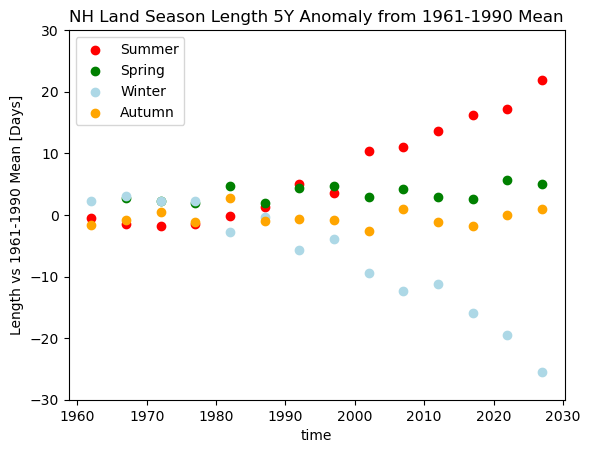

In [78]:
# sel(time=slice('1990','2025')).
nh_land_anom_5Y.SummerLength.plot.scatter(label="Summer", color="red")
nh_land_anom_5Y.SpringLength.plot.scatter(label="Spring", color="green")
nh_land_anom_5Y.WinterLength.plot.scatter(label="Winter", color="lightblue")
nh_land_anom_5Y.AutumnLength.plot.scatter(label="Autumn", color="orange")
plt.legend()
plt.ylim(-30,30)
plt.title("NH Land Season Length 5Y Anomaly from 1961-1990 Mean")
plt.ylabel("Length vs 1961-1990 Mean [Days]")
#plt.xlim(dt(1989,1,1),dt(2025,12,31))


In [193]:
# create data for bar plot
# get fraction of 365 days that are each season each year
x = ds_canesm5_seasons.time.dt.year.values
nh_AL = nh_land_full.AutumnLength.values#/365.0
nh_WL = nh_land_full.WinterLength.values#/365.0
nh_SpL = nh_land_full.SpringLength.values#/365.0
nh_SL = nh_land_full.SummerLength.values#/365.0
nh_sums = nh_AL + nh_WL + nh_SpL + nh_SL
print(nh_sums)

# normalize so each year has same total length and each season is a fraction of that year
nh_ALn = nh_AL/nh_sums
nh_WLn = nh_WL/nh_sums
nh_SpLn = nh_SpL/nh_sums
nh_SLn = nh_SL/nh_sums


# same for SH
sh_AL = sh_land_full.AutumnLength.values#/365.0
sh_WL = sh_land_full.WinterLength.values#/365.0
sh_SpL = sh_land_full.SpringLength.values#/365.0
sh_SL = sh_land_full.SummerLength.values#/365.0
sh_sums = sh_AL + sh_WL + sh_SpL + sh_SL

# normalize so each year has same total length and each season is a fraction of that year
sh_ALn = sh_AL/sh_sums
sh_WLn = sh_WL/sh_sums
sh_SpLn = sh_SpL/sh_sums
sh_SLn = sh_SL/sh_sums

[280.18222304 374.60657023 369.19529502 356.23982274 367.96112796
 368.93238995 373.92867709 369.86825479 365.54491616 360.5837125
 360.60087541 378.39762948 364.46504049 372.64302725 364.77189187
 368.61500259 370.34394462 362.69974795 369.9933074  367.20795463
 374.55934775 362.88218542 368.85915399 367.11165509 362.60874033
 369.0674691  372.12658578 363.82629965 374.12117514 359.52661556
 367.42017023 365.12884638 375.97416862 359.49948317 367.13801108
 360.80810829 378.51415257 368.08311877 372.97714413 367.28396748
 358.10954498 376.52995917 357.87835986 361.17336208 375.09579394
 371.52729586 365.21277316 375.69851074 360.50947443 360.4534159
 372.31275494 354.85519096 385.61664102 359.93770661 367.09153522
 366.95904429 373.26477181 363.82331888 357.25341339 373.52960192
 375.05902843 364.17481814 365.68571106 366.75435161 372.73167467
 362.22805215 364.05489206 365.2021142  367.67347423 367.40796067
 379.72423055 361.59296961 363.09580619 375.97581813 365.34450398
 368.9503364

### NH Land Stacked Bars

Update - order needs to be Spring - Summer - Autumn - Winter starting with 1962 (first year with full set, and winter starts in 1962 but spans into 1963)

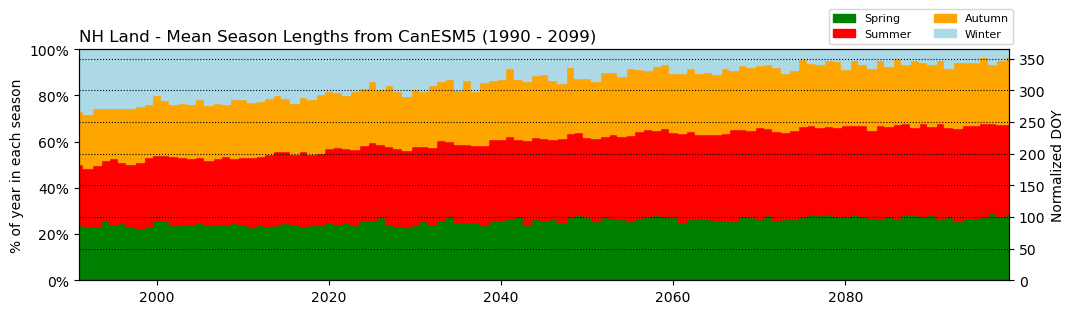

In [198]:
fs=8
barWidth = 1

fig = plt.figure(figsize=(12,3))

ax = fig.add_subplot()

# Spring
plt.bar(x, nh_SpLn, color='green', edgecolor='green', width=barWidth, label="Spring")
# Summer
plt.bar(x, nh_SLn, bottom = nh_SpLn, color='red', edgecolor='red', width=barWidth, label="Summer")
# Autumn bars
plt.bar(x, nh_ALn, bottom = nh_SpLn + nh_SLn, color='orange', edgecolor='orange', width=barWidth, label="Autumn")
# Winter, on top of the first ones - in NH spans two calendar years
plt.bar(x, nh_WLn, bottom = nh_SpLn + nh_SLn + nh_ALn, color='lightblue', edgecolor='lightblue', width=barWidth, label="Winter")


 
# labels, etc
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(1))
plt.ylabel("% of year in each season")

# Put a legend to the right of the current axis
#get handles and labels https://www.statology.org/matplotlib-legend-order/
handles, labels = plt.gca().get_legend_handles_labels()

#specify order of items in legend
order = [0,1,2,3]

#add legend to plot
# plt.legend()
ax.legend([handles[idx] for idx in order],[labels[idx] for idx in order], fontsize=fs, bbox_to_anchor=(0.8, 1), loc="lower left", ncol=2)#'upper left', bbox_to_anchor=(1, 1))

ax.set_ylim(0,1)

# add right labels
ax2 = ax.twinx()

ax2.set_ylim(0,365)
ax2.set_ylabel("Normalized DOY")

# adjust x axis so legend is visible
plt.xlim(1991,2099)
plt.grid(axis='both', which = 'both', linestyle=':', color="black")


plt.title("NH Land - Mean Season Lengths from CanESM5 (1990 - 2099)", loc='left')

plt.show()

### SH Land Stacked Bars

Update - order needs to be Autumn - Winter - Spring - Summer starting with 1962 (first year with full set, and summer starts in 1962 but spans into 1963)

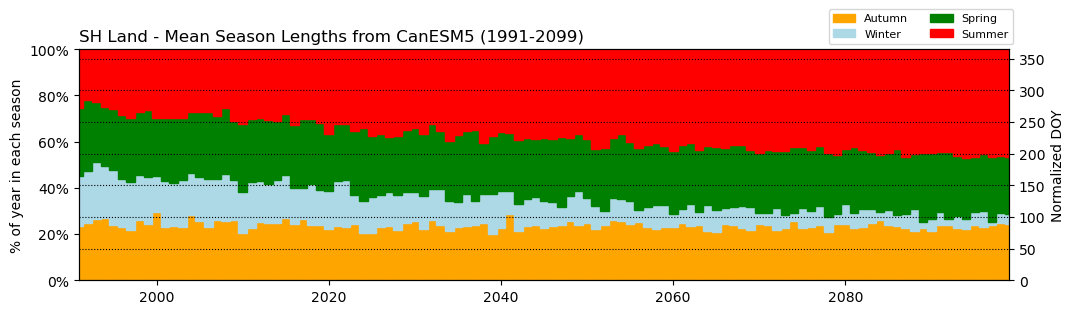

In [199]:
fs=8
barWidth = 1

fig = plt.figure(figsize=(12,3))

ax = fig.add_subplot()

# Autumn bars
plt.bar(x, sh_ALn, color='orange', edgecolor='orange', width=barWidth, label="Autumn")
# Winter, on top of the first ones
plt.bar(x, sh_WLn, bottom=sh_ALn, color='lightblue', edgecolor='lightblue', width=barWidth, label="Winter")
# Spring
plt.bar(x, sh_SpLn, bottom= sh_ALn + sh_WLn, color='green', edgecolor='green', width=barWidth, label="Spring")
# Summer
plt.bar(x, sh_SLn, bottom= sh_ALn + sh_WLn + sh_SpLn, color='red', edgecolor='red', width=barWidth, label="Summer")
 
# labels, etc
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(1))
plt.ylabel("% of year in each season")

# Put a legend to the right of the current axis
#get handles and labels https://www.statology.org/matplotlib-legend-order/
handles, labels = plt.gca().get_legend_handles_labels()

#specify order of items in legend
order = [0,1,2,3]

#add legend to plot
# plt.legend()
ax.legend([handles[idx] for idx in order],[labels[idx] for idx in order], fontsize=fs, bbox_to_anchor=(0.8, 1), loc="lower left", ncol=2)#'upper left', bbox_to_anchor=(1, 1))

ax.set_ylim(0,1)

# add right labels
ax2 = ax.twinx()

ax2.set_ylim(0,365)
ax2.set_ylabel("Normalized DOY")

# adjust x axis so legend is visible
plt.xlim(1991,2099)
plt.grid(axis='both', which = 'both', linestyle=':', color="black")


plt.title("SH Land - Mean Season Lengths from CanESM5 (1991-2099)", loc='left')

plt.show()

### Function for any lat/lon

In [200]:
def MakeSeasonsPlot(input_lat, input_lon):
    '''

    Function that produces the length of each season over 1961-2025 (ds_seasons is already loaded) as a stacked bar plot.
    In in SH, starts with Autumn in 1962 (summer spans two calendar years), and in NH starts with Spring in 1962 (winter spans two years).

    Args:
        input_lat, input_lon: the lat and lon of the cell of interest, note func uses method='nearest'
        to get the nearest grid square from ERA5 at 0.25 deg resolution. Lat [-90,90], Lon [-180, 180]
        
    Returns:
        nothing
        
    Example:
        # for Vancouver, BC
        MakeSeasonsPlot(49.246, -123.116)

    '''

    if ((input_lat > -23.5) & (input_lat < 23.5)):
        print("Grid location not in midlatitudes! Results may be unexpected!")

    # filter data to nearest location of interested 
    ds = ds_canesm5_seasons.sel(lat=input_lat, lon=input_lon, method='nearest')
    ds = ds.sel(time=slice('1990','2100'))

    # remove years with no winter for plot
    #ds = ds.where(ds.WinterLength > 0)
    
    # create data for bar plot
    # get fraction of 365 days that are each season each year
    x = ds.time.dt.year.values
    # AL = ds.AutumnLength.values/365.0
    # WL = ds.WinterLength.values/365.0
    # SpL = ds.SpringLength.values/365.0
    # SL = ds.SummerLength.values/365.0

    AL = np.abs(ds.AutumnLength/365.0)
    WL = np.abs(ds.WinterLength/365.0)
    SpL = np.abs(ds.SpringLength/365.0)
    SL = np.abs(ds.SummerLength/365.0)
    sums = AL + WL + SpL + SL
    
    # what if WL == 0?
    sums = xr.where((ds["WinterLength"] == 0), AL + SpL + SL, AL + WL + SpL + SL)
    
    # normalize so each year has same total length and each season is a fraction of that year
    ALn = AL/sums
    WLn = WL/sums
    SpLn = SpL/sums
    SLn = SL/sums

    # plotting
    fs=8
    barWidth = 1
    
    fig = plt.figure(figsize=(12,3))
    ax = fig.add_subplot()

    if (input_lat <= -23.5):
        # Autumn bars
        plt.bar(x, ALn, color='orange', edgecolor='orange', width=barWidth, label="Autumn")
        # Winter, on top of the first ones
        plt.bar(x, WLn, bottom=ALn, color='lightblue', edgecolor='lightblue', width=barWidth, label="Winter")
        # Spring
        plt.bar(x, SpLn, bottom= ALn + WLn, color='green', edgecolor='green', width=barWidth, label="Spring")
        # Summer
        plt.bar(x, SLn, bottom= ALn + WLn + SpLn, color='red', edgecolor='red', width=barWidth, label="Summer")

    else:
        # Spring
        plt.bar(x, SpLn, color='green', edgecolor='green', width=barWidth, label="Spring")
        # Summer
        plt.bar(x, SLn, bottom = SpLn, color='red', edgecolor='red', width=barWidth, label="Summer")
        # Autumn bars
        plt.bar(x, ALn, bottom = SpLn + SLn, color='orange', edgecolor='orange', width=barWidth, label="Autumn")
        # Winter, on top of the first ones - in NH spans two calendar years
        plt.bar(x, WLn, bottom = SpLn + SLn + ALn, color='lightblue', edgecolor='lightblue', width=barWidth, label="Winter")

    # labels, etc
    plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(1))
    plt.ylabel("% of year in each season")
    ax.xaxis.set_minor_locator(MultipleLocator(5))
    
    # Put a legend to the right of the current axis
    handles, labels = plt.gca().get_legend_handles_labels()
        
    #specify order of items in legend
    order = [0,1,2,3]
    
    #add legend to plot
    ax.legend([handles[idx] for idx in order],[labels[idx] for idx in order], fontsize=fs, bbox_to_anchor=(0.8, 1), loc="lower left", ncol=2)#'upper left', bbox_to_anchor=(1, 1))
    
    ax.set_ylim(0,1)
    
    # add right labels
    ax2 = ax.twinx()
    
    ax2.set_ylim(0,365)
    ax2.set_ylabel("Normalized DOY")   
    # limit x to complete data regardless of hemisphere
    plt.xlim(1991,2099)
    plt.grid(axis='both', which = 'both', linestyle=':', color="black")
    
    plt.title("Seasons from CanESM5 for nearest cell to ["+str(input_lat)+", "+str(input_lon)+"]", loc='left')
    plt.show()

### Zonal Season Length Plots

In [ ]:
# get function from SpringAndAutumn...CMIP6 script